# Avocado-Preisvorhersage mittels SVR

Dieses Notebook enthält den vollständigen Workflow zur **Support Vector Regression (SVR)**
für den vorverarbeiteten Avocado-Datensatz.

Der Workflow umfasst:

1. das Laden der vordefinierten Trainings- und Testdaten,
2. die Rekonstruktion der im Haupt-Avocado-Notebook verwendeten Merkmalsgruppen,
3. eine chronologische Kreuzvalidierung mit wachsendem Zeitfenster (Expanding-Year-Ansatz) unter ausschließlicher Verwendung der Trainingsdaten,
4. den Vergleich von Merkmalskombinationen: nur Preis, Preis + Volumen sowie Preis + Volumen + Saisonalität,
5. die Optimierung von SVR-Hyperparametern und Kernel,
6. Diagnosen zum Vergleich von Training und Validierung,
7. einen Kernel-Vergleich,
8. die abschließende Evaluierung anhand des unangetasteten Testdatensatzes,
9. den Vergleich mit einfachen Zeitreihen-Baselines,
10. die Erstellung von Vorhersage- und Residuen-Plots.

Der Testdatensatz wird **nicht für GridSearchCV verwendet**.


In [1]:
# ============================================================
# 1. IMPORTS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score


In [2]:
# LOAD PREPROCESSED TRAIN / TEST DATA

X_train = np.loadtxt("preprocessed_x_train.csv", delimiter=",")
X_test  = np.loadtxt("preprocessed_x_test.csv", delimiter=",")
y_train = np.loadtxt("preprocessed_y_train.csv", delimiter=",")
y_test  = np.loadtxt("preprocessed_y_test.csv", delimiter=",")

feature_names = [
    "year",
    "sin_year",
    "cos_year",
    "price_lag_1w",
    "price_lag_2w",
    "price_lag_4w",
    "volume_lag_1w",
    "volume_lag_2w",
    "volume_lag_4w"
]

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nFeature order:")
for i, name in enumerate(feature_names):
    print(i, name)

print("\nTraining years:", np.unique(X_train[:, 0].astype(int)))
print("Test years    :", np.unique(X_test[:, 0].astype(int)))


X_train: (249, 9)
X_test : (48, 9)
y_train: (249,)
y_test : (48,)

Feature order:
0 year
1 sin_year
2 cos_year
3 price_lag_1w
4 price_lag_2w
5 price_lag_4w
6 volume_lag_1w
7 volume_lag_2w
8 volume_lag_4w

Training years: [2015 2016 2017 2018 2019]
Test years    : [2020]


## Merkmalsgruppen

Um die Struktur des ursprünglichen Avocado-Notebooks nachzubilden, werden drei Merkmalsgruppen definiert. Die Spalte `year` wird für die zeitliche Aufteilung verwendet, jedoch nicht direkt als Prädiktor eingesetzt.

- **A: Nur Preis** — Preisverzögerungen (Lags) von 1, 2 und 4 Wochen.
- **B: Preis + Volumen** — Preisverzögerungen sowie Volumenverzögerungen von 1, 2 und 4 Wochen.
- **C: Preis + Volumen + Saisonalität** — Merkmalsgruppe B zuzüglich Sinus-/Cosinus-Saisonalität.

In [3]:

# FEATURE SETS


feature_sets = {
    "A: Price only": [3, 4, 5],
    "B: Price + Volume": [3, 4, 5, 6, 7, 8],
    "C: Price + Volume + Seasonality": [1, 2, 3, 4, 5, 6, 7, 8]
}

for name, idx in feature_sets.items():
    print(name)
    print([feature_names[i] for i in idx])
    print()


A: Price only
['price_lag_1w', 'price_lag_2w', 'price_lag_4w']

B: Price + Volume
['price_lag_1w', 'price_lag_2w', 'price_lag_4w', 'volume_lag_1w', 'volume_lag_2w', 'volume_lag_4w']

C: Price + Volume + Seasonality
['sin_year', 'cos_year', 'price_lag_1w', 'price_lag_2w', 'price_lag_4w', 'volume_lag_1w', 'volume_lag_2w', 'volume_lag_4w']



## Chronologische Kreuzvalidierung

Die Kreuzvalidierung basiert ausschließlich auf dem **Trainingsdatensatz**. Für jeden Validierungs-Fold werden alle vorangegangenen Jahre für das Training und das darauffolgende Jahr für die Validierung verwendet. Der unabhängige Testdatensatz bleibt somit bis zur abschließenden Evaluierung unangetastet.

In [4]:

# EXPANDING-YEAR CROSS-VALIDATION ON TRAINING DATA ONLY


train_years = X_train[:, 0].astype(int)
unique_train_years = sorted(np.unique(train_years))

year_splits = []

for validation_year in unique_train_years[1:]:
    train_idx = np.where(train_years < validation_year)[0]
    val_idx   = np.where(train_years == validation_year)[0]

    if len(train_idx) > 0 and len(val_idx) > 0:
        year_splits.append((train_idx, val_idx))

print("Chronological CV folds:")
for fold, (train_idx, val_idx) in enumerate(year_splits, start=1):
    years_fit = np.unique(train_years[train_idx])
    year_val = np.unique(train_years[val_idx])
    print(
        f"Fold {fold}: Train = {years_fit.tolist()} "
        f"--> Validation = {year_val.tolist()}"
    )


Chronological CV folds:
Fold 1: Train = [2015] --> Validation = [2016]
Fold 2: Train = [2015, 2016] --> Validation = [2017]
Fold 3: Train = [2015, 2016, 2017] --> Validation = [2018]
Fold 4: Train = [2015, 2016, 2017, 2018] --> Validation = [2019]


## Vergleich der SVR-Merkmalsmengen

Vor der umfassenden Hyperparametersuche werden die drei Merkmalsmengen anhand einer einheitlichen SVR-Konfiguration verglichen. Dies beantwortet die Frage, ob Informationen zu Handelsvolumen und Saisonalität das Modell über die reine Betrachtung der jüngsten Preisentwicklung hinaus verbessern.

In [5]:

# BASE SVR AND FEATURE-SET COMPARISON


base_svr = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVR(
        kernel="sigmoid",
        C=1.0,
        epsilon=0.01,
        gamma=0.01
    ))
])

def evaluate_fold(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred)
    }

feature_results = []

for feature_set_name, cols in feature_sets.items():

    X_fs = X_train[:, cols]

    for fold, (train_idx, val_idx) in enumerate(year_splits, start=1):

        model = clone(base_svr)

        X_fit = X_fs[train_idx]
        X_val = X_fs[val_idx]
        y_fit = y_train[train_idx]
        y_val = y_train[val_idx]

        model.fit(X_fit, y_fit)
        pred_val = model.predict(X_val)

        metrics = evaluate_fold(y_val, pred_val)

        feature_results.append({
            "Feature_Set": feature_set_name,
            "Fold": fold,
            **metrics
        })

feature_results = pd.DataFrame(feature_results)

feature_summary = (
    feature_results
    .groupby("Feature_Set")[["MAE", "RMSE", "R2"]]
    .mean()
    .reset_index()
    .sort_values("MAE")
)

print("AVERAGE SVR CROSS-VALIDATION PERFORMANCE")
print(feature_summary.to_string(index=False))

best_feature_set = feature_summary.iloc[0]["Feature_Set"]
best_feature_cols = feature_sets[best_feature_set]

print("\nBest feature set according to CV MAE:")
print(best_feature_set)
print([feature_names[i] for i in best_feature_cols])


AVERAGE SVR CROSS-VALIDATION PERFORMANCE
                    Feature_Set      MAE     RMSE       R2
                  A: Price only 0.170492 0.219838 0.368310
              B: Price + Volume 0.170826 0.221335 0.355158
C: Price + Volume + Seasonality 0.175623 0.223353 0.346033

Best feature set according to CV MAE:
A: Price only
['price_lag_1w', 'price_lag_2w', 'price_lag_4w']


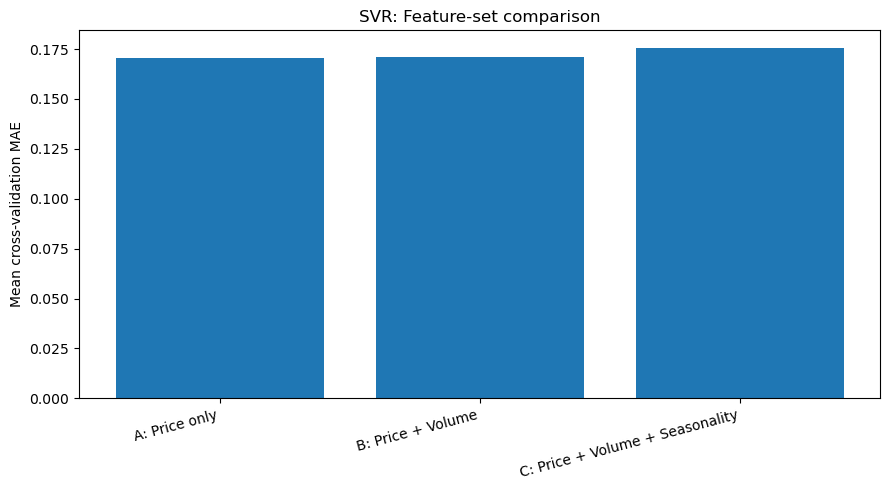

In [6]:

# FEATURE-SET COMPARISON PLOT


plt.figure(figsize=(9, 5))

x = np.arange(len(feature_summary))
plt.bar(x, feature_summary["MAE"])

plt.xticks(
    x,
    feature_summary["Feature_Set"],
    rotation=15,
    ha="right"
)

plt.ylabel("Mean cross-validation MAE")
plt.title("SVR: Feature-set comparison")
plt.tight_layout()
plt.show()


## SVR-Hyperparameteroptimierung

Der beste Merkmalssatz aus dem vorherigen Schritt wird für eine detaillierte SVR-Grid-Search verwendet.
Dabei werden lineare, RBF-, polynomiale und Sigmoid-Kernfunktionen verglichen. Die Auswahl der Hyperparameter erfolgt anhand der chronologischen Trainings-Folds, wobei der **MAE** als Metrik für das Refitting dient.
RMSE und \(R^2\) werden als zusätzliche Bewertungsmetriken gespeichert.

In [7]:
# SVR PIPELINE AND HYPERPARAMETER GRID
svr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVR())
])

svr_grid = [

    # Linear kernel
    {
        "model__kernel": ["linear"],
        "model__C": [0.01, 0.1, 1, 10, 100],
        "model__epsilon": [0.01, 0.05, 0.1, 0.2]
    },

    # RBF kernel
    {
        "model__kernel": ["rbf"],
        "model__C": [0.1, 1, 10, 100],
        "model__epsilon": [0.01, 0.05, 0.1, 0.2],
        "model__gamma": ["scale", 0.001, 0.01, 0.1, 1]
    },

    # Polynomial kernel
    {
        "model__kernel": ["poly"],
        "model__C": [0.1, 1, 10, 100],
        "model__epsilon": [0.01, 0.05, 0.1, 0.2],
        "model__gamma": ["scale", 0.01, 0.1],
        "model__degree": [2, 3, 4]
    },

    # Sigmoid kernel
    {
        "model__kernel": ["sigmoid"],
        "model__C": [0.1, 1, 10, 100],
        "model__epsilon": [0.01, 0.05, 0.1, 0.2],
        "model__gamma": ["scale", 0.001, 0.01, 0.1]
    }
]

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}


In [8]:

# 8. GRID SEARCH — TRAINING DATA ONLY
X_train_svr = X_train[:, best_feature_cols]
X_test_svr  = X_test[:, best_feature_cols]

grid_svr = GridSearchCV(
    estimator=svr_pipeline,
    param_grid=svr_grid,
    cv=year_splits,
    scoring=scoring,
    refit="MAE",
    n_jobs=-1,
    return_train_score=True,
    verbose=1
)

grid_svr.fit(X_train_svr, y_train)
best_svr = grid_svr.best_estimator_
print("\nBest feature set:")
print(best_feature_set)
print("\nBest SVR parameters:")
print(grid_svr.best_params_)
print("\nBest CV MAE:")
print(-grid_svr.best_score_)


Fitting 4 folds for each of 308 candidates, totalling 1232 fits

Best feature set:
A: Price only

Best SVR parameters:
{'model__C': 1, 'model__epsilon': 0.01, 'model__gamma': 0.01, 'model__kernel': 'sigmoid'}

Best CV MAE:
0.17049224189621165


In [9]:

# TRAIN / VALIDATION DIAGNOSTICS FOR BEST SVR
best_idx = grid_svr.best_index_
cv_results = grid_svr.cv_results_
mean_train_mae = -cv_results["mean_train_MAE"][best_idx]
mean_val_mae   = -cv_results["mean_test_MAE"][best_idx]

std_train_mae = cv_results["std_train_MAE"][best_idx]
std_val_mae   = cv_results["std_test_MAE"][best_idx]

mean_val_rmse = -cv_results["mean_test_RMSE"][best_idx]
mean_val_r2   = cv_results["mean_test_R2"][best_idx]

print("Best SVR train/CV diagnostics")
print("--------------------------------")
print(f"Mean train MAE      = {mean_train_mae:.6f}")
print(f"Mean validation MAE = {mean_val_mae:.6f}")
print(f"Train MAE std       = {std_train_mae:.6f}")
print(f"Validation MAE std  = {std_val_mae:.6f}")
print(f"Validation RMSE     = {mean_val_rmse:.6f}")
print(f"Validation R2       = {mean_val_r2:.6f}")
print(f"MAE generalization gap = {mean_val_mae - mean_train_mae:.6f}")

fold_diagnostics = []

for i in range(len(year_splits)):
    fold_diagnostics.append({
        "Fold": i + 1,
        "Train_MAE": -cv_results[f"split{i}_train_MAE"][best_idx],
        "Validation_MAE": -cv_results[f"split{i}_test_MAE"][best_idx],
        "Validation_RMSE": -cv_results[f"split{i}_test_RMSE"][best_idx],
        "Validation_R2": cv_results[f"split{i}_test_R2"][best_idx]
    })

fold_diagnostics = pd.DataFrame(fold_diagnostics)

print("\nFold-wise diagnostics:")
print(fold_diagnostics.to_string(index=False))


Best SVR train/CV diagnostics
--------------------------------
Mean train MAE      = 0.131938
Mean validation MAE = 0.170492
Train MAE std       = 0.016219
Validation MAE std  = 0.025612
Validation RMSE     = 0.219838
Validation R2       = 0.368310
MAE generalization gap = 0.038554

Fold-wise diagnostics:
 Fold  Train_MAE  Validation_MAE  Validation_RMSE  Validation_R2
    1   0.112924        0.139381         0.196444       0.516443
    2   0.121331        0.172586         0.225200       0.476778
    3   0.138400        0.209806         0.252710       0.031633
    4   0.155097        0.160196         0.204999       0.448387


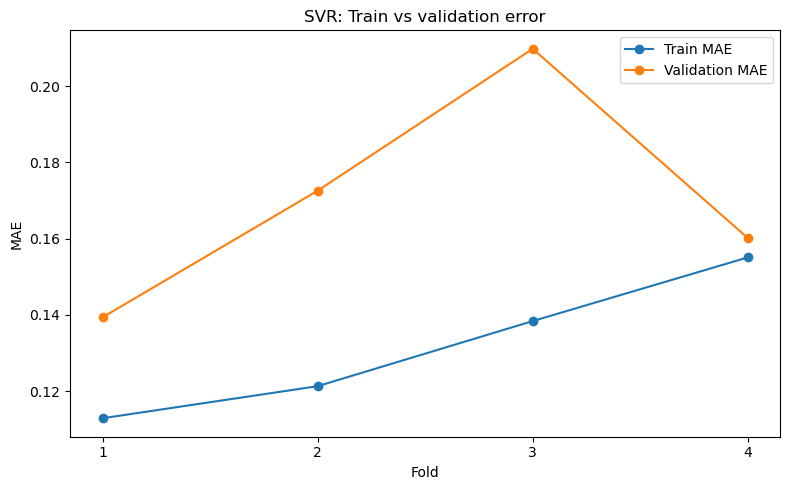

In [10]:
# 10. TRAIN VS VALIDATION MAE BY FOLD
plt.figure(figsize=(8, 5))
plt.plot(fold_diagnostics["Fold"],    fold_diagnostics["Train_MAE"],    marker="o",    label="Train MAE")
plt.plot(    fold_diagnostics["Fold"],    fold_diagnostics["Validation_MAE"],    marker="o",    label="Validation MAE")
plt.xlabel("Fold")
plt.ylabel("MAE")
plt.title("SVR: Train vs validation error")
plt.xticks(fold_diagnostics["Fold"])
plt.legend()
plt.tight_layout()
plt.show()


## Kernel comparison

For each kernel, the parameter combination with the lowest cross-validation MAE
is extracted. This makes it possible to compare the best achievable performance
of the different SVR kernel families.


In [11]:

# BEST RESULT FOR EACH SVR KERNEL
svr_results = pd.DataFrame(grid_svr.cv_results_)

svr_results["MAE"] = -svr_results["mean_test_MAE"]
svr_results["RMSE"] = -svr_results["mean_test_RMSE"]
svr_results["R2"] = svr_results["mean_test_R2"]

best_kernel_results = (
    svr_results
    .sort_values("MAE")
    .groupby("param_model__kernel", as_index=False)
    .first()
    .sort_values("MAE")
    .reset_index(drop=True)
)

kernel_columns = [
    "param_model__kernel",
    "param_model__C",
    "param_model__epsilon",
    "param_model__gamma",
    "param_model__degree",
    "MAE",
    "RMSE",
    "R2"
]

# Some parameters do not exist for every kernel; ensure columns are available.
for col in kernel_columns:
    if col not in best_kernel_results.columns:
        best_kernel_results[col] = np.nan

print(best_kernel_results[kernel_columns].to_string(index=False))


param_model__kernel  param_model__C  param_model__epsilon param_model__gamma  param_model__degree      MAE     RMSE       R2
            sigmoid            1.00                  0.01               0.01                  NaN 0.170492 0.219838 0.368310
             linear            0.01                  0.01               None                  NaN 0.170513 0.219849 0.368264
                rbf            1.00                  0.05               0.01                  NaN 0.171702 0.218914 0.373486
               poly          100.00                  0.20               0.01                  3.0 0.210978 0.264778 0.115400


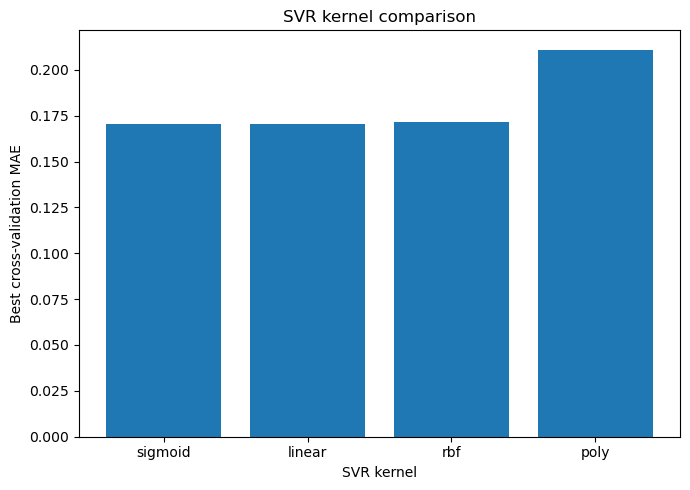

In [12]:
# KERNEL COMPARISON PLOT
plt.figure(figsize=(7, 5))

plt.bar(
    best_kernel_results["param_model__kernel"].astype(str),
    best_kernel_results["MAE"]
)

plt.xlabel("SVR kernel")
plt.ylabel("Best cross-validation MAE")
plt.title("SVR kernel comparison")
plt.tight_layout()
plt.show()


## Final test-set prediction

Only after model selection is complete is the independent test set used.
The optimized SVR is fitted on all training observations and evaluated once on
the test set using MAE, RMSE, and \(R^2\).


In [13]:

# 13. FINAL SVR TEST-SET EVALUATION
y_pred_svr = best_svr.predict(X_test_svr)

test_mae = mean_absolute_error(y_test, y_pred_svr)
test_rmse = root_mean_squared_error(y_test, y_pred_svr)
test_r2 = r2_score(y_test, y_pred_svr)

print("FINAL SVR TEST PERFORMANCE")
print("--------------------------")
print(f"MAE  = {test_mae:.6f}")
print(f"RMSE = {test_rmse:.6f}")
print(f"R2   = {test_r2:.6f}")


FINAL SVR TEST PERFORMANCE
--------------------------
MAE  = 0.161049
RMSE = 0.206075
R2   = -0.196963


In [14]:

# SIMPLE TIME-SERIES BASELINES
all_prices = np.concatenate([y_train, y_test])
test_start = len(y_train)

moving_average_predictions = []
ewma_predictions = []

window = 4
span = 4

for i in range(test_start, len(all_prices)):

    history = all_prices[:i]

    moving_average_predictions.append(
        np.mean(history[-window:])
    )

    ewma_predictions.append(
        pd.Series(history)
        .ewm(span=span, adjust=False)
        .mean()
        .iloc[-1]
    )

moving_average_predictions = np.asarray(moving_average_predictions)
ewma_predictions = np.asarray(ewma_predictions)

moving_average_mae = mean_absolute_error(
    y_test,
    moving_average_predictions
)

ewma_mae = mean_absolute_error(
    y_test,
    ewma_predictions
)

baseline_comparison = pd.DataFrame({
    "Method": [
        "SVR",
        "Moving Average (4)",
        "EWMA (span=4)"
    ],
    "MAE": [
        test_mae,
        moving_average_mae,
        ewma_mae
    ]
}).sort_values("MAE")

print("\nTEST MAE: SVR VS BASELINES")
print(baseline_comparison.to_string(index=False))



TEST MAE: SVR VS BASELINES
            Method      MAE
               SVR 0.161049
Moving Average (4) 0.166302
     EWMA (span=4) 0.176811


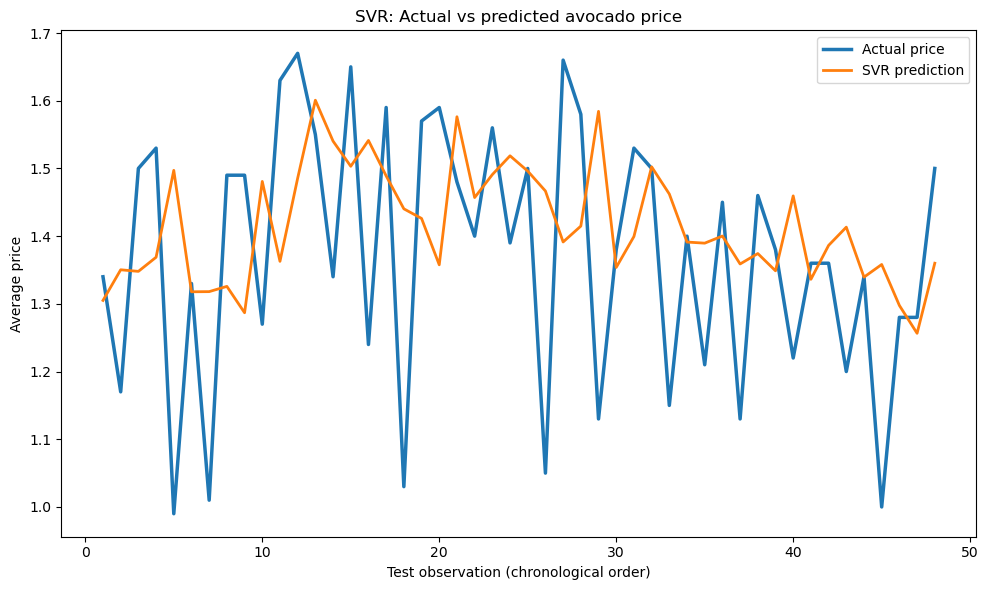

In [15]:

# TEST PREDICTION PLOT
test_index = np.arange(1, len(y_test) + 1)
plt.figure(figsize=(10, 6))
plt.plot(test_index,    y_test,    linewidth=2.5,    label="Actual price")
plt.plot(test_index,    y_pred_svr,    linewidth=2,    label="SVR prediction")
plt.xlabel("Test observation (chronological order)")
plt.ylabel("Average price")
plt.title("SVR: Actual vs predicted avocado price")
plt.legend()
plt.tight_layout()
plt.savefig("conventional_avocado_prediction_2020_SVR.png", dpi=300, bbox_inches="tight")
plt.show()


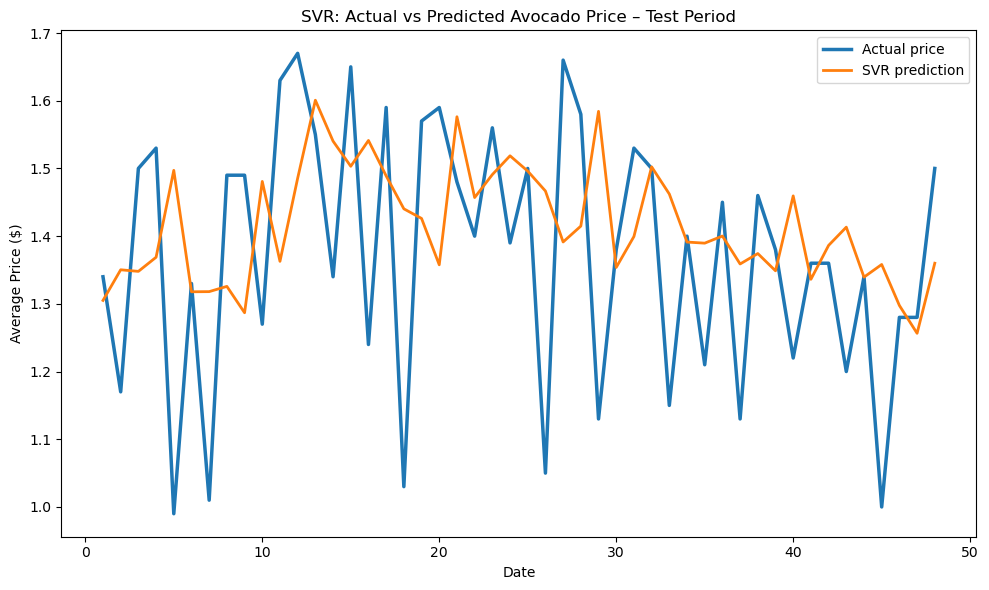

In [16]:
plt.figure(figsize=(10, 6))

plt.plot(test_index, y_test, linewidth=2.5, label="Actual price")
plt.plot(test_index, y_pred_svr, linewidth=2, label="SVR prediction")
plt.xlabel("Date")
plt.ylabel("Average Price ($)")
plt.title("SVR: Actual vs Predicted Avocado Price – Test Period")
plt.legend()
plt.tight_layout()
plt.savefig("SVR_actual_vs_predicted_test.png",    dpi=300,    bbox_inches="tight")
plt.show()

Residual mean: -0.043118466333841254
Residual std : 0.2015138408610129


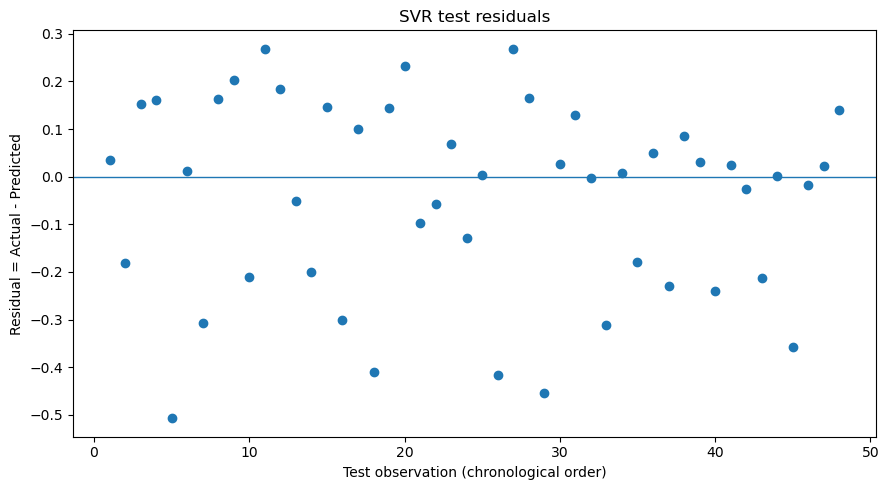

In [17]:

# RESIDUAL ANALYSIS
residuals = y_test - y_pred_svr
print("Residual mean:", residuals.mean())
print("Residual std :", residuals.std())
plt.figure(figsize=(9, 5))
plt.scatter(np.arange(1, len(residuals) + 1), residuals)
plt.axhline(0, linewidth=1)
plt.xlabel("Test observation (chronological order)")
plt.ylabel("Residual = Actual - Predicted")
plt.title("SVR test residuals")
plt.tight_layout()
plt.show()


In [18]:
# FINAL SVR SUMMARY TABLE
final_summary = pd.DataFrame({    "Stage": [        "Cross-validation",        "Independent test"    ],    "MAE": [        mean_val_mae,        test_mae    ],
    "RMSE": [        mean_val_rmse,        test_rmse    ],
    "R2": [        mean_val_r2,        test_r2    ]})

print("FINAL SVR SUMMARY")
print(final_summary.to_string(index=False))
print("\nSelected feature set:")
print(best_feature_set)
print("\nSelected hyperparameters:")
print(grid_svr.best_params_)


FINAL SVR SUMMARY
           Stage      MAE     RMSE        R2
Cross-validation 0.170492 0.219838  0.368310
Independent test 0.161049 0.206075 -0.196963

Selected feature set:
A: Price only

Selected hyperparameters:
{'model__C': 1, 'model__epsilon': 0.01, 'model__gamma': 0.01, 'model__kernel': 'sigmoid'}


In [19]:
# SVR: TRAIN / VALIDATION / TEST
# Mean MAE ± standard deviation
# for LINEAR, SIGMOID and RBF kernels
from sklearn.base import clone
import numpy as np
import pandas as pd

kernels_to_compare = ["linear", "sigmoid", "rbf"]

svr_comparison_rows = []

for kernel in kernels_to_compare:
  
    # Find best GridSearch result for this kernel
    kernel_results = svr_results[
        svr_results["param_model__kernel"] == kernel
    ].copy()
    # Smallest CV MAE = best parameter combination
    best_idx = kernel_results["MAE"].idxmin()

    best_params = svr_results.loc[
        best_idx, "params"
    ]
    print("\n========================================")
    print("Kernel:", kernel)
    print("Best parameters:")
    print(best_params)

    
    #  Build best model for this kernel
    

    model = clone(svr_pipeline)

    model.set_params(        **best_params    )

        # 3. TRAIN + VALIDATION fold errors
    
    train_fold_mae = []
    validation_fold_mae = []

    for train_idx, val_idx in year_splits:

        model_fold = clone(model)

        X_fold_train = X_train_svr[train_idx]
        X_fold_val   = X_train_svr[val_idx]

        y_fold_train = y_train[train_idx]
        y_fold_val   = y_train[val_idx]

        model_fold.fit(
            X_fold_train,
            y_fold_train
        )

        pred_train = model_fold.predict(
            X_fold_train
        )

        pred_val = model_fold.predict(
            X_fold_val
        )

        train_fold_mae.append(
            mean_absolute_error(
                y_fold_train,
                pred_train
            )
        )

        validation_fold_mae.append(
            mean_absolute_error(
                y_fold_val,
                pred_val
            )
        )

    
    # 4. Fit complete training set and evaluate independent test set
   

    model.fit(
        X_train_svr,
        y_train
    )

    pred_test = model.predict(
        X_test_svr
    )

    test_absolute_errors = np.abs(
        y_test - pred_test
    )
    # Results
    train_mean = np.mean(train_fold_mae)
    train_std  = np.std(train_fold_mae)
    val_mean = np.mean(validation_fold_mae)
    val_std  = np.std(validation_fold_mae)
    test_mean = np.mean(test_absolute_errors)
    test_std  = np.std(test_absolute_errors)
    svr_comparison_rows.append({
        "Algorithmus":
            f"SVR ({kernel})",

        "Validierung":
            f"{val_mean:.4f} ± {val_std:.4f}",

        "Train":
            f"{train_mean:.4f} ± {train_std:.4f}",

        "Test":
            f"{test_mean:.4f} ± {test_std:.4f}"
    })


svr_comparison_table = pd.DataFrame(
    svr_comparison_rows
)

print("\nSVR COMPARISON")
print(svr_comparison_table.to_string(index=False))


Kernel: linear
Best parameters:
{'model__C': 0.01, 'model__epsilon': 0.01, 'model__kernel': 'linear'}

Kernel: sigmoid
Best parameters:
{'model__C': 1, 'model__epsilon': 0.01, 'model__gamma': 0.01, 'model__kernel': 'sigmoid'}

Kernel: rbf
Best parameters:
{'model__C': 1, 'model__epsilon': 0.05, 'model__gamma': 0.01, 'model__kernel': 'rbf'}

SVR COMPARISON
  Algorithmus     Validierung           Train            Test
 SVR (linear) 0.1705 ± 0.0256 0.1319 ± 0.0162 0.1612 ± 0.1285
SVR (sigmoid) 0.1705 ± 0.0256 0.1319 ± 0.0162 0.1610 ± 0.1286
    SVR (rbf) 0.1717 ± 0.0246 0.1310 ± 0.0163 0.1627 ± 0.1230
